# Voucher float: liability, breakage and the redemption curve

A gift-voucher service issues, redeems and expires vouchers. Every state change goes into an
outbox, a relay puts it on Kinesis, a Firehose transform Lambda checks it and derives its cohort
and age, and Firehose `COPY`s it into Redshift. This notebook reads the far end of that chain and
asks the three questions a finance team has about voucher float:

1. **How much do we owe?** The outstanding liability, every day.
2. **How much will never be claimed?** Breakage: issued value that lapses unredeemed. Under
   IFRS 15 B46 a seller recognises expected breakage as revenue in proportion to the pattern of
   redemptions, so the expected rate is a number the books need *before* a cohort has closed.
3. **When do people redeem?** The redemption curve, by days since issue.

The data is simulated, and on purpose: the simulator fixes the answer to question 2 before the
first voucher is issued (an 18% never-redeem share, Weibull redemption delays, a 30-day term),
so the warehouse's estimate for a cohort that is days old can be checked against the truth
rather than against another estimate.

Everything here runs locally. The first cell builds `_localrun/` with
`local-development/run_local.py` if it is not there: about 50,000 vouchers driven through the
service's REST endpoints, relayed, transformed and loaded into DuckDB, in about two minutes.

In [1]:
import json
import shutil
import sqlite3
import sys
from datetime import date, datetime
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

PROJECT = Path.cwd()
LOCAL = PROJECT / "_localrun"
sys.path.insert(0, str(PROJECT))
sys.path.insert(0, str(PROJECT / "local-development"))

if not (LOCAL / "warehouse.duckdb").exists():
    import run_local
    run_local.run()
else:
    print("using the chain already built in _localrun/")

truth = json.loads((PROJECT / "data" / "simulation-truth.json").read_text())
con = duckdb.connect(str(LOCAL / "warehouse.duckdb"), read_only=True)


def q(sql, *params):
    frame = con.execute(sql, list(params)).fetchdf()
    for column in frame.columns:  # DuckDB sums are 128-bit; pandas reads them as floats
        if column.endswith(("_cents", "_vouchers")):
            frame[column] = frame[column].astype("int64")
    return frame


BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.figsize": (10, 4), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "lines.linewidth": 2, "legend.frameon": False,
    "legend.labelcolor": MUTED, "font.size": 10,
})

simulated   49,209 vouchers, 10,004,336.78 issued, as of 2026-11-02T00:00:00Z; 37,144 redeemed, 11,235 expired, 830 open
relayed     97,588 events in 196 put_records calls
delivered   97,588 records in 98 batches: 97,588 Ok, 0 ProcessingFailed
landed      97,588 rows in voucher_events_raw
reconciled  service 171,795.16 on 830 vouchers, warehouse 171,795.16 on 830; difference 0 cents; 0 duplicates dropped, 0 orphan exits, 0 vouchers with two exits
breakage    pooled life table 0.2379 against a true 0.2397; the open 2026-10 cohort, 814 vouchers still open: 0.2250 projected, 0.0237 naive
seconds     simulate 128.5, relay 1.3, firehose 3.9, warehouse 0.5


## The known truth

What the simulator was told, and what it therefore guarantees. The true breakage rate is
$0.18 + 0.82\,e^{-(30/9)^{0.8}}$: the never-redeemers, plus the redeemers whose delay outruns the
30-day term. Amounts are drawn independently of redemption, so the rate is the same by count and
by value.

In [2]:
p = truth["parameters"]
pd.DataFrame([
    ("period", f"{p['start'][:10]} for {p['days']} days, as of {truth['as_of']}"),
    ("issue pattern", f"Poisson, {p['weekday_rate']:.0f} a weekday, x{p['saturday_factor']} Saturday, "
                      f"x{p['sunday_factor']} Sunday, x{p['month_end_factor']} on the last "
                      f"{p['month_end_business_days']} business days of the month"),
    ("never redeem", f"{p['never_redeem_share']:.0%}"),
    ("redemption delay", f"Weibull, shape {p['delay_shape']}, scale {p['delay_scale_days']} days"),
    ("term", f"{p['term_days']} days"),
    ("sweep outage", f"{p['sweep_outage'][0]} to {p['sweep_outage'][1]}, caught up the next day"),
    ("true breakage rate", f"{truth['true_breakage_rate']:.4f}"),
], columns=["", "value"]).set_index("")

,value
,
period,"2024-11-04 for 728 days, as of 2026-11-02T00:0..."
issue pattern,"Poisson, 72 a weekday, x0.55 Saturday, x0.35 S..."
never redeem,18%
redemption delay,"Weibull, shape 0.8, scale 9.0 days"
term,30 days
sweep outage,"2026-03-09 to 2026-03-15, caught up the next day"
true breakage rate,0.2397


In [3]:
r = truth["realised"]
pd.DataFrame([
    ("vouchers issued", f"{r['issued']:,}"),
    ("value issued", f"{r['issued_cents'] / 100:,.2f}"),
    ("redeemed", f"{r['redeemed']:,}"),
    ("expired", f"{r['expired']:,}"),
    ("open at as_of", f"{r['open_at_as_of']:,}"),
    ("redemptions refused because the voucher had lapsed (409)", f"{r['refused_lapsed']:,}"),
    ("issue retries answered with the original voucher", f"{r['replays']:,}"),
    ("outbox events", f"{r['outbox_events']:,}"),
], columns=["what the service did", ""]).set_index("what the service did")

,
what the service did,
vouchers issued,"49,209"
value issued,"10,004,336.78"
redeemed,"37,144"
expired,"11,235"
open at as_of,830
redemptions refused because the voucher had lapsed (409),"2,717"
issue retries answered with the original voucher,997
outbox events,"97,588"


## 1. The liability, every day

`daily_liability` adds each voucher's value on its issue day and takes it off on its exit day,
in UTC, and keeps a running total. Every date comes from the events themselves - `issued_at`, or
an exit's `occurred_at` - never from when an event arrived.

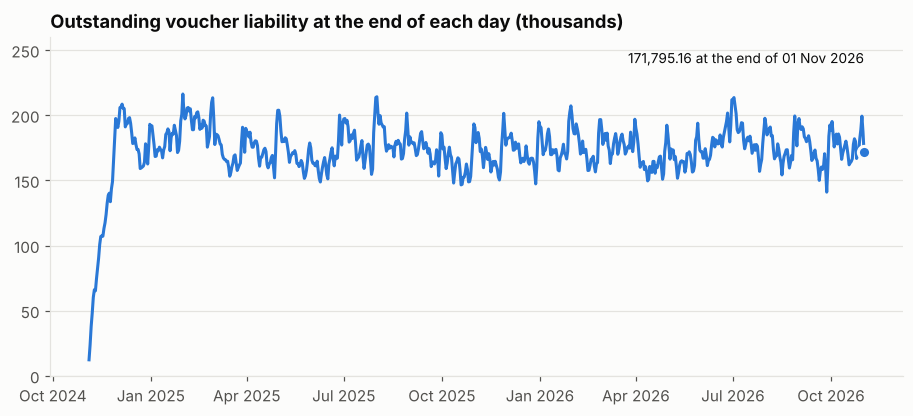

mean 173,086, range 12,288 to 216,270


In [4]:
daily = q("select * from daily_liability order by day")
daily["day"] = pd.to_datetime(daily["day"])
fig, ax = plt.subplots()
ax.plot(daily["day"], daily["outstanding_cents"] / 100_000, color=BLUE)
ax.set_title("Outstanding voucher liability at the end of each day (thousands)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_ylim(0, 260)
last = daily.iloc[-1]
ax.plot([last["day"]], [last["outstanding_cents"] / 100_000], "o", color=BLUE, markersize=8,
        markeredgecolor="#fcfcfb", markeredgewidth=2)
ax.text(last["day"], 240, f"{last['outstanding_cents'] / 100:,.2f} at the end of {last['day']:%d %b %Y}",
        ha="right", color=INK, fontsize=9)
plt.show()
print(f"mean {daily['outstanding_cents'].mean() / 100:,.0f}, "
      f"range {daily['outstanding_cents'].min() / 100:,.0f} to {daily['outstanding_cents'].max() / 100:,.0f}")

The saw-tooth is the issue pattern: each month-end's corporate reward run doubles that day's
issuance, and the float it adds runs off over the next 30 days.

### A week without the sweep

The expiry sweep did not run from 9 to 15 March 2026. The vouchers that lapsed that week stayed
`unredeemed` in the service's table until it caught up on the 16th, and their `expired` events
reached the stream after redemptions dated up to a week later. Because an expired event is
dated at the voucher's `expires_at`, the warehouse puts each lapse on the day it happened. The
orange line is what a report would show if it dated each lapse at the sweep that recorded it -
the service's own status column, read day by day. Even with the sweep on time, the grey line,
that report runs a day behind the warehouse: the 01:00 sweep records the previous day's lapses.
The outage is the gap between orange and grey.

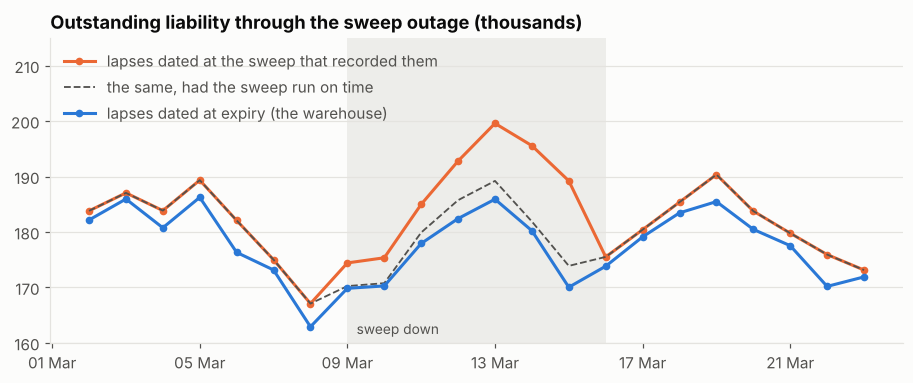

on time, the sweep-dated series sits above the warehouse by exactly that day's lapses on 728 of 728 days: 4,181.12 on 8 March, 1,679.22 on 16 March
the outage alone, against the same series with the sweep on time: 4,181.12 on 9 March to 15,337.74 on 15 March; largest difference from 16 March on: 0.00
against the warehouse, the day's own lapses included: 4,581.12 to 19,187.74


In [5]:
service = sqlite3.connect(LOCAL / "voucher-service.db")
vouchers = pd.read_sql("select amount_cents, issued_at, expires_at, redeemed_at, swept_at from vouchers", service)
service.close()
day = lambda s: pd.to_datetime(s.str[:10])
redeemed, swept = vouchers["redeemed_at"].notna(), vouchers["swept_at"].notna()
# On time, a lapse is recorded by the first 01:00 sweep at or after its expiry.
expires = pd.to_datetime(vouchers["expires_at"], format="%Y-%m-%dT%H:%M:%SZ")
on_time_sweep = ((expires - pd.Timedelta(hours=1)).dt.ceil("D") + pd.Timedelta(hours=1)).dt.floor("D")


def dated_at_the_sweep(sweep_day):
    flows = pd.concat([
        pd.DataFrame({"day": day(vouchers["issued_at"]), "cents": vouchers["amount_cents"]}),
        pd.DataFrame({"day": day(vouchers.loc[redeemed, "redeemed_at"]), "cents": -vouchers.loc[redeemed, "amount_cents"]}),
        pd.DataFrame({"day": sweep_day[swept], "cents": -vouchers.loc[swept, "amount_cents"]}),
    ])
    return flows.groupby("day")["cents"].sum().cumsum()


series = (daily.set_index("day")[["outstanding_cents", "expired_cents"]]
          .join(dated_at_the_sweep(day(vouchers["swept_at"])).rename("by_sweep"), how="outer")
          .join(dated_at_the_sweep(on_time_sweep).rename("on_time"), how="outer"))
series = series.loc[:daily["day"].max()].ffill().fillna({"expired_cents": 0})
window = series.loc["2026-03-02":"2026-03-23"]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(pd.Timestamp("2026-03-09"), pd.Timestamp("2026-03-16"), color=GRID, alpha=0.6, lw=0)
ax.plot(window.index, window["by_sweep"] / 100_000, color=ORANGE, marker="o", markersize=4, label="lapses dated at the sweep that recorded them")
ax.plot(window.index, window["on_time"] / 100_000, color=MUTED, lw=1.2, ls="--", label="the same, had the sweep run on time")
ax.plot(window.index, window["outstanding_cents"] / 100_000, color=BLUE, marker="o", markersize=4, label="lapses dated at expiry (the warehouse)")
ax.set_ylim(160, 215)
ax.text(pd.Timestamp("2026-03-09 06:00"), 161, "sweep down", va="bottom", color=MUTED, fontsize=9)
ax.set_title("Outstanding liability through the sweep outage (thousands)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.legend(loc="upper left")
plt.show()

lag = (series["by_sweep"] - series["outstanding_cents"]) / 100
outage_only = (series["by_sweep"] - series["on_time"]) / 100
outage = outage_only.loc["2026-03-09":"2026-03-15"]
one_day = (series["on_time"] - series["outstanding_cents"]) == series["expired_cents"]
print(f"on time, the sweep-dated series sits above the warehouse by exactly that day's lapses on"
      f" {one_day.sum()} of {len(one_day)} days: {lag['2026-03-08']:,.2f} on 8 March, {lag['2026-03-16']:,.2f} on 16 March")
print(f"the outage alone, against the same series with the sweep on time: {outage.min():,.2f} on"
      f" {outage.idxmin().day} {outage.idxmin():%B} to {outage.max():,.2f} on {outage.idxmax().day} {outage.idxmax():%B};"
      f" largest difference from 16 March on: {outage_only.loc['2026-03-16':].abs().max():,.2f}")
print(f"against the warehouse, the day's own lapses included: {lag.loc['2026-03-09':'2026-03-15'].min():,.2f}"
      f" to {lag.loc['2026-03-09':'2026-03-15'].max():,.2f}")

`tests/test_warehouse.py` runs the same comparison end to end on a small simulation twice -
once with the sweep on time, once a week late - and asserts the two daily liability series are
identical, and that before the catch-up's events arrive the outage days really are overstated.

## 2. Breakage by issue month

A cohort is the vouchers issued in one calendar month. Once none of them is still redeemable,
its breakage is simply expired value over issued value. Every month but the last two is closed.

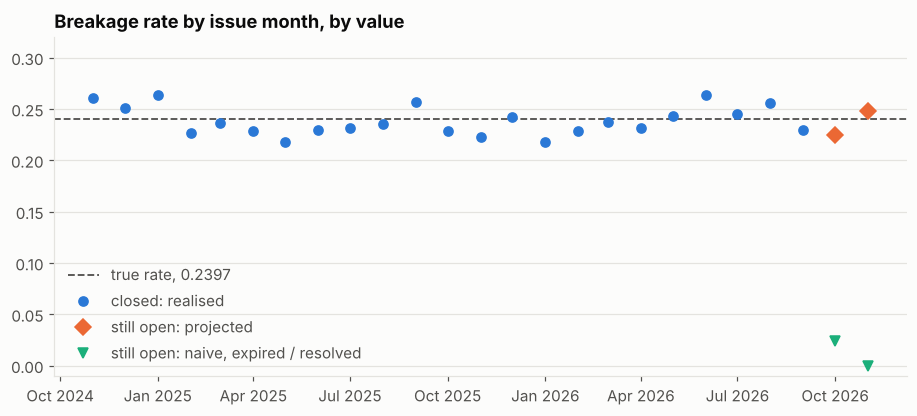

closed cohorts: mean 0.2384, sd 0.0142, range 0.2178 to 0.2636
pooled life table: 0.2379; true: 0.2397


In [6]:
cohorts = q("select * from breakage_by_issue_month order by issue_month")
cohorts["issue_month"] = pd.to_datetime(cohorts["issue_month"])
closed = cohorts[cohorts["open_vouchers"] == 0]
young = cohorts[cohorts["open_vouchers"] > 0]

fig, ax = plt.subplots()
ax.axhline(truth["true_breakage_rate"], color=MUTED, lw=1.2, ls="--", label=f"true rate, {truth['true_breakage_rate']:.4f}")
ax.plot(closed["issue_month"], closed["realised_breakage_rate"], color=BLUE, marker="o", markersize=6, lw=0, label="closed: realised")
ax.plot(young["issue_month"], young["breakage_rate"], color=ORANGE, marker="D", markersize=7, lw=0, label="still open: projected")
ax.plot(young["issue_month"], young["naive_breakage_rate"], color=AQUA, marker="v", markersize=7, lw=0, label="still open: naive, expired / resolved")
ax.set_ylim(-0.01, 0.32)
ax.set_title("Breakage rate by issue month, by value")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="lower left")
plt.show()

spread = closed["realised_breakage_rate"]
pooled = q("select max(expired_share) as rate from redemption_life_table where scope = 'pooled'")["rate"][0]
print(f"closed cohorts: mean {spread.mean():.4f}, sd {spread.std():.4f}, range {spread.min():.4f} to {spread.max():.4f}")
print(f"pooled life table: {pooled:.4f}; true: {truth['true_breakage_rate']:.4f}")

The closed months scatter about the true rate with a standard deviation of about a point and a
half. That is what about 2,000 vouchers a month give once they are weighted by value: a 1,000.00
voucher counts twenty times a 50.00 one, and 3% of vouchers are 1,000.00.

The open months are where the estimator earns its keep. The **naive** rate - expired over
expired plus redeemed, ignoring what is still open - is close to zero for October, because the
vouchers that redeem early are already in it and the ones that will lapse are not. The
**projected** rate adds, for every open voucher, its value times the chance that a voucher of its
age goes on to lapse, read off the pooled life table below.

## 3. The redemption curve

`redemption_life_table` is an actuarial life table by days since issue, in cents. Redeemed and
expired are competing exits; a voucher still open at `as_of` is censored at its age and counts
half on its last day. Its cumulative incidences are the curve.

In [7]:
life = q("select * from redemption_life_table where scope = 'pooled' order by day")
life[["day", "at_risk_vouchers", "redeemed_vouchers", "expired_vouchers", "censored_vouchers",
      "redeem_hazard", "survival", "redeemed_share", "expired_share"]].round(4).set_index("day").T

day,0,1,2,3,4,5,6,7,8,9,...,21,22,23,24,25,26,27,28,29,30
at_risk_vouchers,49209.0000,42669.0000,38560.0000,35139.0000,32282.0000,29884.0000,27853.0000,26025.0000,24530.0000,23125.0000,...,13879.000,13499.0000,13140.0000,12820.0000,12488.0000,12190.0000,11909.0000,11676.0000,11434.0000,11235.0000
redeemed_vouchers,6524.0000,4080.0000,3324.0000,2762.0000,2314.0000,1991.0000,1792.0000,1486.0000,1381.0000,1261.0000,...,376.000,349.0000,306.0000,317.0000,281.0000,268.0000,216.0000,238.0000,191.0000,0.0000
expired_vouchers,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,11235.0000
censored_vouchers,16.0000,29.0000,97.0000,95.0000,84.0000,40.0000,36.0000,9.0000,24.0000,36.0000,...,4.000,10.0000,14.0000,15.0000,17.0000,13.0000,17.0000,4.0000,8.0000,0.0000
redeem_hazard,0.1327,0.0959,0.0841,0.0786,0.0698,0.0650,0.0635,0.0572,0.0568,0.0544,...,0.029,0.0247,0.0252,0.0252,0.0233,0.0223,0.0161,0.0204,0.0177,0.0000
survival,0.8673,0.7841,0.7182,0.6617,0.6156,0.5756,0.5390,0.5081,0.4793,0.4532,...,0.284,0.2769,0.2699,0.2631,0.2570,0.2513,0.2472,0.2422,0.2379,0.0000
redeemed_share,0.1327,0.2159,0.2818,0.3383,0.3844,0.4244,0.4610,0.4919,0.5207,0.5468,...,0.716,0.7231,0.7301,0.7369,0.7430,0.7487,0.7528,0.7578,0.7621,0.7621
expired_share,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,...,0.000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.2379


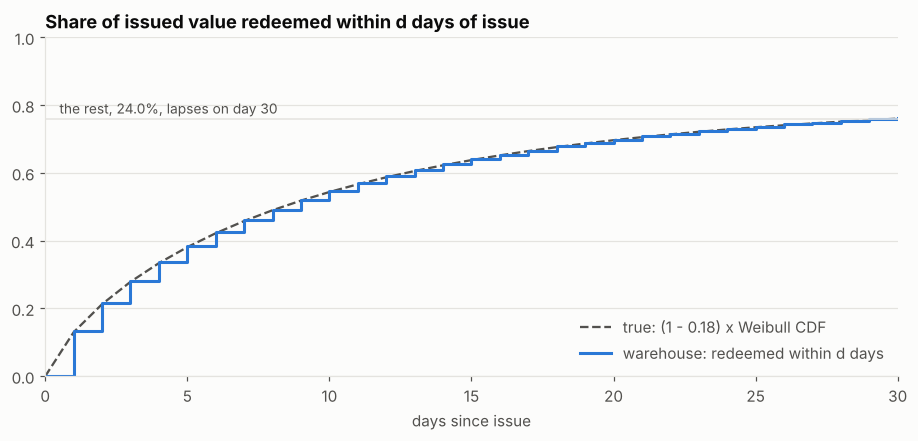

,1,3,7,14,21,29,30
warehouse,0.1327,0.2818,0.4610,0.6254,0.7076,0.7578,0.7621
true,0.1299,0.2787,0.4581,0.6226,0.7056,0.7560,0.7603


In [8]:
true_curve = pd.Series({int(k): v for k, v in truth["true_redeemed_within_days"].items()})
estimated = pd.Series([0.0] + list(life.set_index("day")["redeemed_share"].reindex(range(30)).ffill()), index=range(31))

fig, ax = plt.subplots()
ax.plot(true_curve.index, true_curve.values, color=MUTED, lw=1.5, ls="--", label="true: (1 - 0.18) x Weibull CDF")
ax.step(estimated.index, estimated.values, where="post", color=BLUE, label="warehouse: redeemed within d days")
ax.axhline(1 - truth["true_breakage_rate"], color=GRID, lw=1)
ax.text(0.5, 1 - truth["true_breakage_rate"] + 0.015, f"the rest, {truth['true_breakage_rate']:.1%}, lapses on day 30",
        color=MUTED, fontsize=9)
ax.set_xlim(0, 30)
ax.set_ylim(0, 1)
ax.set_xlabel("days since issue")
ax.set_title("Share of issued value redeemed within d days of issue")
ax.legend(loc="lower right")
plt.show()
pd.DataFrame({"warehouse": estimated, "true": true_curve}).loc[[1, 3, 7, 14, 21, 29, 30]].round(4).T

Half the value that will ever be redeemed is redeemed within five days, and the curve is still
rising at day 29: a Weibull shape below 1 is a hazard that falls with age but never reaches zero,
which is exactly the population a 30-day term cuts off.

## 4. The estimator against the truth, on young cohorts

The real test of a breakage estimator is a cohort that has barely started. At each month end
from January 2025, the warehouse is rewound - `warehouse_as_of` set to midnight on the 1st, so
every event dated later is invisible and every open voucher is censored at its age then - and the
month just ended is estimated. Its vouchers are 0 to 30 days old at that moment. Each estimate is
set against the truth and against what that cohort actually did once it closed.

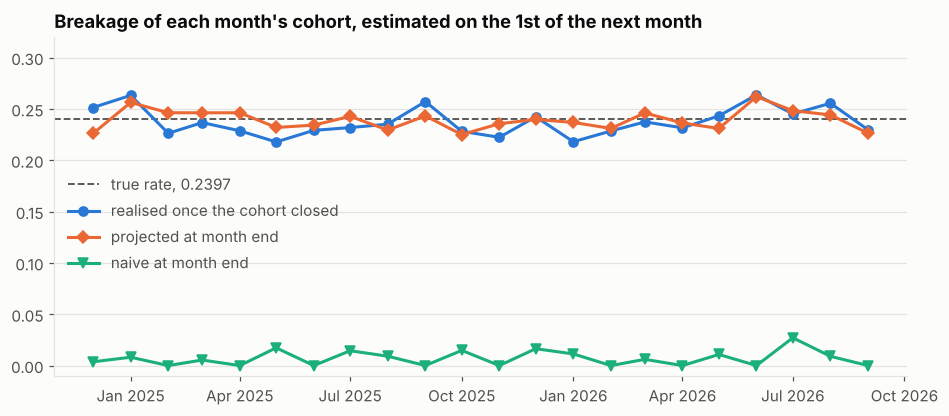

,open at month end,of,naive,projected,realised once closed
cohort,,,,,
2024-12-01,961,2144,0.0037,0.2260,0.2513
2025-01-01,1025,2204,0.0081,0.2563,0.2631
2025-02-01,966,1938,0.0000,0.2463,0.2262
2025-03-01,914,2027,0.0054,0.2462,0.2366
2025-04-01,985,2021,0.0000,0.2462,0.2286
2025-05-01,857,2026,0.0173,0.2319,0.2178
2025-06-01,954,2043,0.0000,0.2342,0.2291
2025-07-01,1003,2176,0.0144,0.2427,0.2318
2025-08-01,883,2093,0.0091,0.2294,0.2351


In [9]:
shutil.copy(LOCAL / "warehouse.duckdb", LOCAL / "backtest.duckdb")
rewind = duckdb.connect(str(LOCAL / "backtest.duckdb"))
final = cohorts.set_index("issue_month")["realised_breakage_rate"]
rows = []
for first in pd.date_range("2025-01-01", "2026-10-01", freq="MS"):
    as_of = first.to_pydatetime()
    month = (first - pd.offsets.MonthBegin(1)).date()
    rewind.execute("delete from warehouse_as_of")
    rewind.execute("insert into warehouse_as_of values (?)", [as_of])
    open_vouchers, issued, naive, projected = rewind.execute(
        "select open_vouchers, issued_vouchers, naive_breakage_rate, breakage_rate"
        " from breakage_by_issue_month where issue_month = ?", [month]).fetchone()
    rows.append({"cohort": pd.Timestamp(month), "open at month end": int(open_vouchers),
                 "of": int(issued), "naive": naive, "projected": projected,
                 "realised once closed": final.get(pd.Timestamp(month))})
rewind.close()
(LOCAL / "backtest.duckdb").unlink()
backtest = pd.DataFrame(rows).set_index("cohort")

fig, ax = plt.subplots()
ax.axhline(truth["true_breakage_rate"], color=MUTED, lw=1.2, ls="--", label=f"true rate, {truth['true_breakage_rate']:.4f}")
ax.plot(backtest.index, backtest["realised once closed"], color=BLUE, marker="o", markersize=6, label="realised once the cohort closed")
ax.plot(backtest.index, backtest["projected"], color=ORANGE, marker="D", markersize=6, label="projected at month end")
ax.plot(backtest.index, backtest["naive"], color=AQUA, marker="v", markersize=6, label="naive at month end")
ax.set_ylim(-0.01, 0.32)
ax.set_title("Breakage of each month's cohort, estimated on the 1st of the next month")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="center left", bbox_to_anchor=(0, 0.45))
plt.show()
backtest.round(4)

In [10]:
scored = backtest.dropna(subset=["realised once closed"])
error_vs_outcome = scored["projected"] - scored["realised once closed"]
error_vs_truth = backtest["projected"] - truth["true_breakage_rate"]
naive_vs_truth = backtest["naive"] - truth["true_breakage_rate"]
errors = [error_vs_truth, error_vs_outcome, naive_vs_truth]
pd.DataFrame({
    "mean error": [e.mean() for e in errors],
    "mean absolute error": [e.abs().mean() for e in errors],
    "within a point": [int((e.abs() <= 0.01).sum()) for e in errors],
    "sd": [e.std() for e in errors],
    "largest miss": [e.abs().max() for e in errors],
    "cohorts": [len(e) for e in errors],
}, index=["projected - true rate", "projected - realised once closed", "naive - true rate"]).round(4)

,mean error,mean absolute error,within a point,sd,largest miss,cohorts
projected - true rate,-0.0004,0.0081,16,0.0098,0.0222,22
projected - realised once closed,0.0019,0.0098,12,0.0118,0.0253,22
naive - true rate,-0.2327,0.2327,0,0.0076,0.2397,22


With 40-50% of a cohort still open on the day it is estimated, the projection shows no bias
against the true rate: a mean error of -0.04 points over 22 cohorts. No bias is not the same as
a close single estimate. One month's projection is typically within about a point of the true
rate - a mean absolute error of 0.81 points, 16 of 22 within one, 2.2 at worst - and about a
point from what each cohort went on to do, 2.5 at worst. It sits closer to the truth than the
closed cohorts do, because half of each projection is the pooled history rather than one month's
draw. The naive rate understates breakage by more than twenty points every single month: it is
the number a report gets by counting what has happened, and it would book almost no breakage
revenue on a young cohort.

This backtest is also what caught the one bias the estimator had. An earlier version read an
open voucher's survival at the start of its last day, ignoring the part of that day it had
already come through without redeeming; with day 0's hazard at 13%, that put every young
cohort about half a point low, -0.0060 against the truth on average. It now interpolates across
the day, and `tests/test_warehouse.py` pins the arithmetic on four vouchers.

The projection is only as good as the assumption under it: that a young cohort will redeem the
way the pooled history did. The simulator keeps that true by construction. A real programme that
changed its terms, its channel or its customers would break it, and the cohort table is where it
would show: young projections drifting away from what their cohorts go on to do.

## 5. Reconciliation

The warehouse's outstanding liability is checked against the service's own sum of unredeemed
cents, taken at the same `as_of`; a lost event, such as a redemption that never arrived, moves
the difference. Beside it are three counts that never move it. Exits whose issue never arrived
and vouchers with two exits flag a broken event history the totals cannot show. Copies the dedupe
dropped are informational: the relay delivers at least once by design, and the copies are gone
before anything is summed.

In [11]:
check = q("select * from reconciliation")
check.T.rename(columns={0: ""})

,
taken_at,2026-11-02 00:00:00
service_cents,17179516
warehouse_cents,17179516
difference_cents,0
service_vouchers,830
warehouse_vouchers,830
duplicates_dropped,0
orphan_exits,0
vouchers_with_two_exits,0


In [12]:
row = check.iloc[0]
assert row["difference_cents"] == 0 and row["warehouse_vouchers"] == row["service_vouchers"]
print(f"service {row['service_cents'] / 100:,.2f} on {row['service_vouchers']:,} vouchers = "
      f"warehouse {row['warehouse_cents'] / 100:,.2f} on {row['warehouse_vouchers']:,}: reconciled to the cent")

service 171,795.16 on 830 vouchers = warehouse 171,795.16 on 830: reconciled to the cent


Zero duplicates here because nothing crashed in this run. `tests/test_relay.py` kills the relay
between `put_records` and marking the rows, and `tests/test_warehouse.py` has Firehose deliver
the whole stream twice: the copies share an `event_id`, the dedupe drops them, and the figures
do not move. It also deletes one redemption from the landing table, and the reconciliation shows
a difference of exactly that voucher's value.

## 6. One GraphQL query

The read side of the same Flask app. `voucher` reads the service database, `liability` and
`cohort` read the warehouse views above, and only the finance role may ask.

In [13]:
from voucher_service.app import create_app
from voucher_service.warehouse import DuckDBWarehouse

app = create_app(LOCAL / "voucher-service.db", warehouse=DuckDBWarehouse(connection=con))
client = app.test_client()
token = client.post("/login", json={"username": "finance", "password": "finance-local-only"}).get_json()["access_token"]
code = sqlite3.connect(LOCAL / "voucher-service.db").execute(
    "select code from vouchers where status = 'redeemed' and issued_at >= '2026-10-01' order by issued_at limit 1").fetchone()[0]

query = '''
query Float($code: String!, $asOf: Date!, $month: String!) {
  voucher(code: $code) {
    code status amountCents issuedAt expiresAt redeemedAt
    events { eventType occurredAt publishedAt }
  }
  liability(asOf: $asOf) { asOf outstandingCents outstandingVouchers }
  cohort(month: $month) {
    month issued redeemed expired open breakageRate
    week: redeemedBy(days: 7)
    term: redeemedBy(days: 30)
  }
}'''
response = client.post("/graphql", headers={"Authorization": f"Bearer {token}"},
                       json={"query": query, "variables": {"code": code, "asOf": "2026-11-01", "month": "2026-10"}})
print(response.status_code)
print(json.dumps(response.get_json(), indent=2))

200
{
  "data": {
    "cohort": {
      "breakageRate": 0.22501674522558013,
      "expired": 603834,
      "issued": 42401548,
      "month": "2026-10",
      "open": 16934516,
      "redeemed": 24863198,
      "term": 0.8069707799427205,
      "week": 0.4466134247831443
    },
    "liability": {
      "asOf": "2026-11-01",
      "outstandingCents": 17179516,
      "outstandingVouchers": 830
    },
    "voucher": {
      "amountCents": 20000,
      "code": "VCH-dee434c7",
      "events": [
        {
          "eventType": "issued",
          "occurredAt": "2026-10-01T07:00:28Z",
          "publishedAt": "2026-11-03T12:55:50Z"
        },
        {
          "eventType": "redeemed",
          "occurredAt": "2026-10-10T20:05:42Z",
          "publishedAt": "2026-11-03T12:55:50Z"
        }
      ],
      "expiresAt": "2026-10-31T07:00:28Z",
      "issuedAt": "2026-10-01T07:00:28Z",
      "redeemedAt": "2026-10-10T20:05:42Z",
      "status": "redeemed"
    }
  }
}


`liability` on 1 November is the reconciled figure. October's `breakageRate` is the projection
from section 2, and its `redeemedBy` comes from October's own life table, so past the first
couple of weeks it rests on the cohort's oldest vouchers alone - fewer than two hundred of them
by day 20 - and runs a few points above the pooled curve. The pooled curve is the one the
projection uses.

In [14]:
con.close()